# Progressive Growing GANs (ProGAN)

## Theory, mathematics, and implementation context

A GAN learns through a two-player game. $G_\theta(z)$ maps noise $z\sim p(z)$ to images and $D_\phi(x)$ scores realism. The minimax objective is $\min_G\max_D\;\mathbb E_{p_{data}}\log D(x)+\mathbb E_z\log(1-D(G(z)))$; the non-saturating generator loss $-\mathbb E_z\log D(G(z))$ usually gives stronger early gradients. ProGAN grows both networks over spatial scales, for example 4→8→16→32 pixels. At each transition, old and new paths blend as $y=(1-\alpha)y_{old}+\alpha y_{new}$ while $\alpha$ ramps from zero to one. This continuation schedule lets coarse structure form before fine detail is introduced.

ProGAN also popularized equalized learning-rate scaling, pixel-wise feature normalization, and minibatch standard deviation. These address signal scale, feature magnitude, and batch-level sample diversity respectively. This notebook implements the ideas on 4,096 CIFAR-10 images at 32×32: a compact teaching model, not a reproduction of the original high-resolution WGAN-GP recipe. Full convergence takes many updates.

## Case study: reproducible small data slice

Images are normalized to [-1,1] for tanh outputs. CIFAR-10 download is handled by torchvision. A fixed subset keeps the comparison affordable.

In [7]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt
torch.manual_seed(7)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
tf=transforms.Compose([transforms.Resize(32),transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
ds=datasets.CIFAR10("./data",train=True,download=True,transform=tf)
loader=DataLoader(Subset(ds,range(4096)),batch_size=64,shuffle=True,num_workers=0,drop_last=True)
print(DEVICE,len(loader.dataset))

Files already downloaded and verified
cpu 4096


## Equalized learning rate and PixelNorm

Equalized learning rate applies fan-in scaling at runtime. PixelNorm normalizes feature channels independently at every spatial position.

In [8]:
class EqConv(nn.Module):
    def __init__(self,ci,co,k,p=0):
        super().__init__(); self.weight=nn.Parameter(torch.randn(co,ci,k,k)); self.bias=nn.Parameter(torch.zeros(co)); self.scale=(ci*k*k)**-.5; self.p=p
    def forward(self,x): return F.conv2d(x,self.weight*self.scale,self.bias,padding=self.p)
class PixelNorm(nn.Module):
    def forward(self,x): return x*torch.rsqrt(x.square().mean(1,keepdim=True)+1e-8)
class Block(nn.Module):
    def __init__(self,ci,co):
        super().__init__(); self.net=nn.Sequential(EqConv(ci,co,3,1),nn.LeakyReLU(.2),PixelNorm(),EqConv(co,co,3,1),nn.LeakyReLU(.2),PixelNorm())
    def forward(self,x): return self.net(x)
BASE_CHANNELS = 128
CHANNELS = {4:BASE_CHANNELS, 8:64, 16:32, 32:16}


## Generator with fade-in transition

ToRGB projections expose every stage. During transition, the old RGB image is upsampled and mixed with the new projection.

In [9]:
class ProGenerator(nn.Module):
    def __init__(self,zdim=128):
        super().__init__(); self.start=nn.Sequential(nn.ConvTranspose2d(zdim,CHANNELS[4],4),nn.LeakyReLU(.2),EqConv(CHANNELS[4],CHANNELS[4],3,1),nn.LeakyReLU(.2),PixelNorm())
        self.blocks=nn.ModuleList([Block(CHANNELS[r//2],CHANNELS[r]) for r in (8,16,32)])
        self.rgb=nn.ModuleList([nn.Conv2d(CHANNELS[r],3,1) for r in (4,8,16,32)])
    def forward(self,z,stage=3,alpha=1.):
        x=self.start(z)
        for i in range(stage):
            previous_stage=x
            x=self.blocks[i](F.interpolate(x,scale_factor=2,mode="nearest"))
            if i==stage-1 and alpha<1:
                new=self.rgb[i+1](x)
                old=self.rgb[i](previous_stage)
                prev=F.interpolate(old,scale_factor=2,mode="nearest")
                return torch.tanh(alpha*new+(1-alpha)*prev)
        return torch.tanh(self.rgb[stage](x))
G=ProGenerator().to(DEVICE); print(G(torch.randn(2,128,1,1,device=DEVICE),stage=3,alpha=.5).shape)


torch.Size([2, 3, 32, 32])


## Discriminator with minibatch statistic

The minibatch statistic adds a channel summarizing feature variation across examples. This compact discriminator uses logistic loss; the original ProGAN used WGAN-GP.

In [10]:
class ProDiscriminator(nn.Module):
    def __init__(self):
        super().__init__(); self.fromrgb=nn.ModuleList([nn.Conv2d(3,CHANNELS[r],1) for r in (4,8,16,32)])
        self.down=nn.ModuleList([Block(CHANNELS[r],CHANNELS[r//2]) for r in (32,16,8)])
        self.final=nn.Sequential(EqConv(CHANNELS[4]+1,CHANNELS[4],3,1),nn.LeakyReLU(.2),nn.Flatten(),nn.Linear(CHANNELS[4]*4*4,1))
    def forward(self,x,stage=3,alpha=1.):
        resolution=(4,8,16,32)[stage]
        if stage>0 and alpha<1:
            new=F.leaky_relu(self.fromrgb[stage](x),.2)
            first_block={1:2,2:1,3:0}[stage]
            new=F.avg_pool2d(self.down[first_block](new),2)
            old_x=F.avg_pool2d(x,2)
            old=F.leaky_relu(self.fromrgb[stage-1](old_x),.2)
            y=alpha*new+(1-alpha)*old
            resolution//=2
        else:
            y=F.leaky_relu(self.fromrgb[stage](x),.2)
        while resolution>4:
            i={32:0,16:1,8:2}[resolution]; y=F.avg_pool2d(self.down[i](y),2); resolution//=2
        stat=(y.var(0,unbiased=False)+1e-8).sqrt().mean().view(1,1,1,1).expand(y.size(0),1,4,4)
        return self.final(torch.cat([y,stat],1))
D=ProDiscriminator().to(DEVICE); print(D(torch.randn(2,3,32,32,device=DEVICE)).shape)


torch.Size([2, 1])


## Progressive training loop (run before sampling)

The model trains successively at 4, 8, 16, and 32 pixels, for 15 epochs per stage (60 total) on the 4,096-image subset. Each new stage fades in over its first eight epochs. The smaller channel counts keep this demonstration lighter than the original ProGAN. On CPU, training can take several minutes; the next cell displays samples from the trained weights, so run this full cell before sampling.

resolution= 4px | epoch=01/15 | alpha=1.00 | G=0.770 | D=1.374
resolution= 4px | epoch=02/15 | alpha=1.00 | G=0.818 | D=1.357
resolution= 4px | epoch=03/15 | alpha=1.00 | G=0.818 | D=1.363
resolution= 4px | epoch=04/15 | alpha=1.00 | G=0.815 | D=1.368
resolution= 4px | epoch=05/15 | alpha=1.00 | G=0.807 | D=1.375
resolution= 4px | epoch=06/15 | alpha=1.00 | G=0.803 | D=1.375
resolution= 4px | epoch=07/15 | alpha=1.00 | G=0.798 | D=1.375
resolution= 4px | epoch=08/15 | alpha=1.00 | G=0.798 | D=1.373
resolution= 4px | epoch=09/15 | alpha=1.00 | G=0.800 | D=1.373
resolution= 4px | epoch=10/15 | alpha=1.00 | G=0.801 | D=1.375
resolution= 4px | epoch=11/15 | alpha=1.00 | G=0.801 | D=1.374
resolution= 4px | epoch=12/15 | alpha=1.00 | G=0.803 | D=1.375
resolution= 4px | epoch=13/15 | alpha=1.00 | G=0.800 | D=1.377
resolution= 4px | epoch=14/15 | alpha=1.00 | G=0.798 | D=1.376
resolution= 4px | epoch=15/15 | alpha=1.00 | G=0.798 | D=1.377
Finished 4px stage in 0.8 min
resolution= 8px | epoch=0

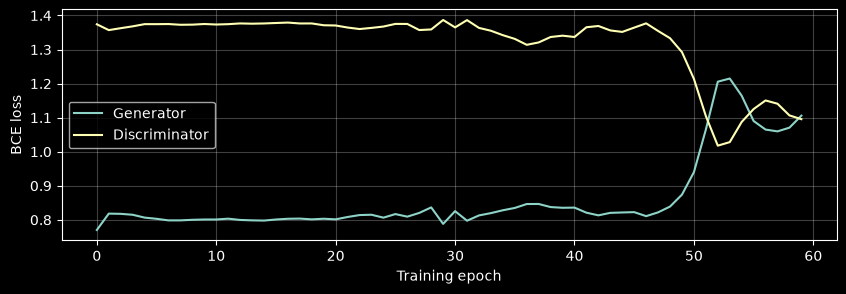

In [11]:
from IPython.display import clear_output
import time
LATENT_DIM = 128
RESOLUTIONS = (4, 8, 16, 32)
EPOCHS_PER_STAGE = 15
FADE_EPOCHS = 8
G = ProGenerator().to(DEVICE)
D = ProDiscriminator().to(DEVICE)
optG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.0, 0.99))
optD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.0, 0.99))
criterion = nn.BCEWithLogitsLoss()
g_history, d_history = [], []
steps_per_epoch = len(loader)
fade_steps = FADE_EPOCHS * steps_per_epoch
for stage, resolution in enumerate(RESOLUTIONS):
    stage_started = time.time()
    for epoch in range(EPOCHS_PER_STAGE):
        g_running, d_running = 0.0, 0.0
        G.train(); D.train()
        for step, (real, _) in enumerate(loader):
            real = real.to(DEVICE)
            if resolution != 32:
                real = F.interpolate(real, size=(resolution, resolution), mode="area")
            batch_size = real.size(0)
            progress = epoch * steps_per_epoch + step
            alpha = 1.0 if stage == 0 else min(1.0, progress / fade_steps)
            z = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
            fake = G(z, stage=stage, alpha=alpha).detach()
            real_targets = torch.full((batch_size, 1), 0.9, device=DEVICE)
            fake_targets = torch.zeros((batch_size, 1), device=DEVICE)
            d_loss = criterion(D(real, stage=stage, alpha=alpha), real_targets) + criterion(D(fake, stage=stage, alpha=alpha), fake_targets)
            optD.zero_grad(set_to_none=True); d_loss.backward(); optD.step()
            z = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
            g_loss = criterion(D(G(z, stage=stage, alpha=alpha), stage=stage, alpha=alpha), torch.ones((batch_size, 1), device=DEVICE))
            optG.zero_grad(set_to_none=True); g_loss.backward(); optG.step()
            g_running += g_loss.item(); d_running += d_loss.item()
        g_history.append(g_running / steps_per_epoch); d_history.append(d_running / steps_per_epoch)
        print(f"resolution={resolution:2d}px | epoch={epoch+1:02d}/{EPOCHS_PER_STAGE} | alpha={alpha:.2f} | G={g_history[-1]:.3f} | D={d_history[-1]:.3f}")
    print(f"Finished {resolution}px stage in {(time.time()-stage_started)/60:.1f} min")
plt.figure(figsize=(10,3)); plt.plot(g_history,label="Generator"); plt.plot(d_history,label="Discriminator"); plt.xlabel("Training epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.grid(alpha=.25);


## Inspect samples and limitations

Compare fixed latent vectors across stages. A healthy fade preserves composition as detail appears. Progressive growth is a curriculum, not a guarantee against mode collapse or poor coverage. Later StyleGAN work abandoned progressive growing while retaining carefully engineered synthesis and regularization.

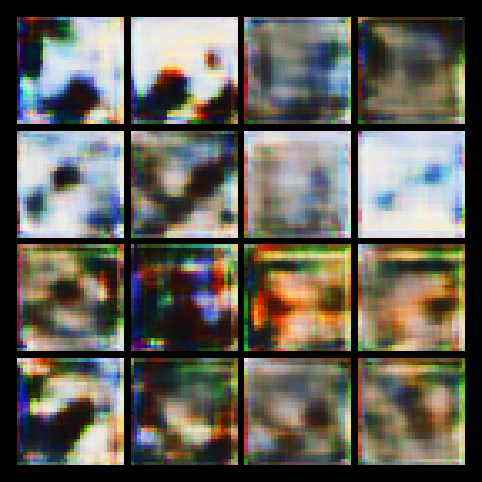

In [12]:
G.eval()
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, 1, 1, device=DEVICE)
    samples = G(z, stage=3, alpha=1.0).cpu()
plt.figure(figsize=(6,6)); plt.axis("off"); plt.imshow(utils.make_grid(samples,nrow=4,normalize=True).permute(1,2,0));


## Key Takeaways

- Progressive growing adds capacity in resolution stages; fade-in blending makes transitions continuous.
- Equalized learning rate, PixelNorm, and minibatch standard deviation address distinct training issues.
- Schedule transitions by examples seen.
- Original ProGAN used more extensive training and WGAN-GP.
- Higher resolution increases compute and data demands; progressive growth alone does not ensure diversity or semantic quality.